In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score

penjualan = pd.read_excel("data_penjualan.xlsx", sheet_name="Penjualan")
pelanggan = pd.read_excel("data_penjualan.xlsx", sheet_name="Pelanggan")

In [2]:
df = penjualan.merge(pelanggan, on="id_pelanggan", how="left")
df["bulan"] = df["tanggal"].dt.month

In [3]:
fitur_kat = ["produk", "kategori", "kota", "sales", "metode_bayar"]
fitur_num=["jumlah", "diskon", "umur", "bulan"]

df[fitur_kat] = df[fitur_kat].fillna("Tidak Diketahui")

x = df[fitur_kat + fitur_num]
y = df["total_bayar"]

In [4]:
x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, random_state=42
)

In [5]:
preprocess = ColumnTransformer(
    [("kat", OneHotEncoder(handle_unknown="ignore"), fitur_kat)],
    remainder="passthrough"    # kolom angka dibiarkan apa adanya
)

In [6]:
model_linear = Pipeline([("pre", preprocess), ("model", LinearRegression())])
model_rf = Pipeline([("pre", preprocess),
                     ("model", RandomForestRegressor(n_estimators=200, random_state=42))])

hasil = {}
for nama, model in [("Linear Regression", model_linear), ("Random Forest", model_rf)]:
    model.fit(x_train, y_train)
    pred = model.predict(x_test)
    hasil[nama] = pred
    print(nama)
    print("  MAE:", round(mean_absolute_error(y_test, pred)))
    print("  R² :", round(r2_score(y_test, pred), 3))

Linear Regression
  MAE: 948120
  R² : 0.845
Random Forest
  MAE: 187428
  R² : 0.992


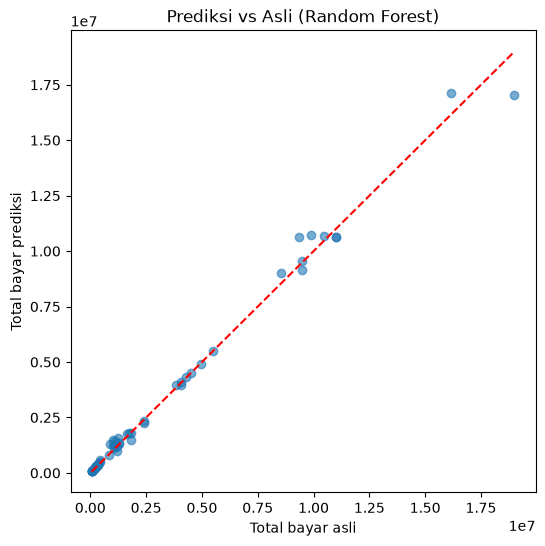

In [7]:
pred = hasil["Random Forest"]

plt.figure(figsize=(6, 6))
plt.scatter(y_test, pred, alpha=0.6)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "r--")  # garis ideal
plt.xlabel("Total bayar asli")
plt.ylabel("Total bayar prediksi")
plt.title("Prediksi vs Asli (Random Forest)")
plt.show()

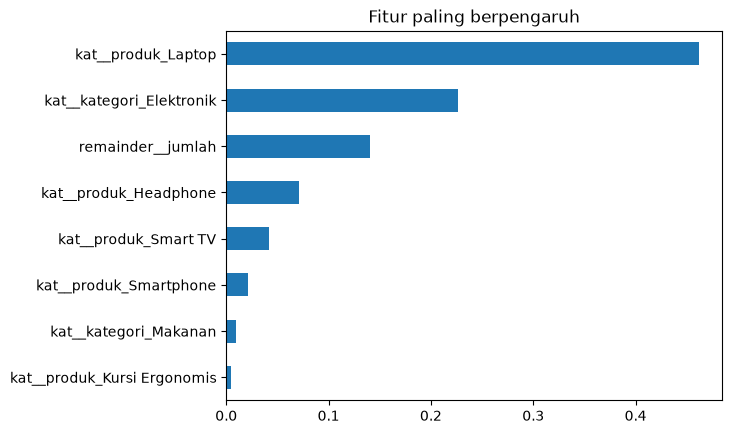

In [8]:
nama_fitur = model_rf.named_steps["pre"].get_feature_names_out()
pentingnya = pd.Series(
    model_rf.named_steps["model"].feature_importances_, index=nama_fitur
).sort_values(ascending=False)

pentingnya.head(8).sort_values().plot(kind="barh")
plt.title("Fitur paling berpengaruh")
plt.show()

In [9]:
transaksi_baru = pd.DataFrame([{
    "produk": "Smartphone", "kategori": "Elektronik", "kota": "Jakarta",
    "sales": "Andi", "metode_bayar": "E-Wallet",
    "jumlah": 2, "diskon": 0.1, "umur": 30, "bulan": 6,
    "harga_satuan": 4500000, "harga_x_jumlah": 9000000
}])

print(model_rf.predict(transaksi_baru)[0])

9102000.0


In [10]:
# 1. Siapkan data
df = penjualan.merge(pelanggan, on="id_pelanggan", how="left")
df["bulan"] = df["tanggal"].dt.month
df["harga_x_jumlah"] = df["harga_satuan"] * df["jumlah"]

fitur_kat = ["produk", "kategori", "kota", "sales", "metode_bayar"]
fitur_num = ["jumlah", "diskon", "umur", "bulan", "harga_satuan", "harga_x_jumlah"]
df[fitur_kat] = df[fitur_kat].fillna("Tidak diketahui")

X = df[fitur_kat + fitur_num]
y = df["total_bayar"]

# 2. Bagi data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. Preprocessing dan model
preprocess = ColumnTransformer(
    [("kat", OneHotEncoder(handle_unknown="ignore"), fitur_kat)],
    remainder="passthrough"
)
model_linear = Pipeline([("pre", preprocess), ("model", LinearRegression())])
model_rf = Pipeline([("pre", preprocess),
                     ("model", RandomForestRegressor(n_estimators=200, random_state=42))])

# 4. Latih dan evaluasi
for nama, model in [("Linear Regression", model_linear), ("Random Forest", model_rf)]:
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    print(nama, "| MAE:", round(mean_absolute_error(y_test, pred)),
          "| R²:", round(r2_score(y_test, pred), 3))

# 5. Prediksi transaksi baru
transaksi_baru = pd.DataFrame([{
    "produk": "Smartphone", "kategori": "Elektronik", "kota": "Jakarta",
    "sales": "Andi", "metode_bayar": "E-Wallet",
    "jumlah": 2, "diskon": 0.1, "umur": 30, "bulan": 6,
    "harga_satuan": 4500000, "harga_x_jumlah": 9000000
}])

print("Manual       :", 4500000 * 2 * 0.9)
print("Linear Reg   :", model_linear.predict(transaksi_baru)[0])
print("Random Forest:", model_rf.predict(transaksi_baru)[0])

Linear Regression | MAE: 167360 | R²: 0.993
Random Forest | MAE: 136618 | R²: 0.992
Manual       : 8100000.0
Linear Reg   : 8487263.520217828
Random Forest: 9026500.0
